# Dependencies

In [2]:
import warnings
warnings.simplefilter("ignore", UserWarning)

In [3]:
import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.bibs import aps
from libs.inference import categorical
from libs.inference import numeric

# Setup

In [4]:
VERSION = 3
FN_PY_INF = f'../../results/v{VERSION}/gender/predictions_py/uniqueChineseAllGivenNames_PYgender_reg_mean_894_class_mean_607_1.csv'
FN_APS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip'
FN_APS_OA_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a_20250120_APSOpenAlex/final_dataset.tar.gz'

PINYIN_OTHERS_DIR = f'../../results/v{VERSION}/gender/predictions_py_others/'
FN_PY_OTHERS = f'{PINYIN_OTHERS_DIR}/<OTHER_PROVIDER>/aps_pinyin_given_names_gendered.csv'
FN_PY_CLAUDE = FN_PY_OTHERS.replace('<OTHER_PROVIDER>', 'claude')
FN_PY_GPT = FN_PY_OTHERS.replace('<OTHER_PROVIDER>', 'gpt')
FN_PY_NAMSOR = FN_PY_OTHERS.replace('<OTHER_PROVIDER>', 'namsor')

PLOT_DIR = f'../../results/v{VERSION}/gender/predictions_py/plots'
PLOT_OTHERS_DIR = f'../../results/v{VERSION}/gender/predictions_py_others/plots'
ios.validate_path(PLOT_DIR)
ios.validate_path(PLOT_OTHERS_DIR)

In [5]:
vis.sns_paper_style()

# Data

## Ours

In [6]:
df_py = ios.load_csv(FN_PY_INF, dtype={'givenname': str, 'py_givenname': str}, keep_default_na=False, low_memory=False)
df_py.rename(columns={'givenname': 'ch_givenname', 'english_one':'py_givenname', 'pred':'ch_pred', 'pred_label':'ch_pred_label'}, inplace=True)
df_py.rename(columns={c:f"py_{c}" for c in df_py.columns if c.startswith('gender_')}, inplace=True)
df_py.loc[:, 'py_gender_mv'] = df_py.apply(lambda row: categorical.infer_gender_by_majority_vote(row['male_label_count'], row['female_label_count'], row['neutral_label_count']), axis=1)
df_py.replace({'py_gender_avg_CNKI': '', 'py_gender_weighted_pop_CNKI': ''}, categorical.np.nan, inplace=True)
df_py.shape


(46144, 19)

In [7]:
df_py.ch_givenname.nunique(), df_py.py_givenname.nunique()

(46144, 18740)

In [8]:
df_py.sample(5)

,ch_givenname,ch_pred,ch_pred_label,pop_CNKI,pop_NU,NLen,py_givenname,unique_name_count,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames,py_gender_mv
22593,庆宣,0.315299,neutral,1,1763.005764,2,qingxuan,5,0.250513,0.253594,0.283830,0.28383,3,1,1,7,11867.657885,庆宣#庆轩#庆选#清旋#清轩,male
16999,因盛,0.189772,male,1,87.654340,2,yinsheng,5,0.195729,0.210106,0.193537,0.193537,5,0,0,11,8195.977658,印生#因盛#寅生#荫晟#银生,male
32121,汉强,0.211412,male,1,3849.348147,2,hanqiang,1,0.211412,0.211412,0.211412,0.211412,1,0,0,1,3849.348147,汉强,male
8752,业民,0.194753,male,2,2155.750960,2,yemin,2,0.238993,0.210334,0.261113,0.261113,1,0,1,3,2442.490801,业旻#业民,neutral
29419,曰通,0.211861,male,1,22.993853,2,yuetong,3,0.274715,0.283520,0.274715,0.274715,2,0,1,3,1508.913903,曰通#越桐#跃通,male


In [9]:
cols_py = ['ch_givenname','py_givenname','ch_pred', 'py_gender_weighted_pop_CNKI', 'py_gender_weighted_pop_NU', 'py_gender_avg_all', 'py_gender_avg_CNKI', 'ch_pred_label', 'py_gender_mv']
df_py[cols_py].head(1)

,ch_givenname,py_givenname,ch_pred,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,ch_pred_label,py_gender_mv
0,㑇,zhou,0.347726,0.281119,0.279068,0.333601,0.280243,male,male


In [10]:
df_py['py_gender_avg_CNKI'].sort_values()

17655    0.143168
16502    0.143168
43450    0.143168
19889    0.143168
29702    0.143168
           ...   
8036          NaN
8057          NaN
8060          NaN
8068          NaN
8087          NaN
Name: py_gender_avg_CNKI, Length: 46144, dtype: object

## APS (Karimi and van Buskirk)

In [11]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS, 'data/genders.csv')

df_aps = ios.pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = ios.pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")

df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
print(f"APS clean ch-py: {df_aps_clean_ch_py.shape} (has_py_ch: {df_aps_clean_ch_py.has_py_ch.value_counts()})")

# APS authors: (874556, 4)
# APS authors names: (948771, 4)
# APS genders: (3, 2)
# APS all authors merged: (948771, 6)
# APS clean ch-py: (874556, 15) (has_py_ch: has_py_ch
# True     2636
# False    1086
# Name: count, dtype: int64)


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)
APS clean ch-py: (874556, 15) (has_py_ch: has_py_ch
True     2636
False    1086
Name: count, dtype: int64)


In [12]:
# Given names with "()" whose names contain pinyin and Hanzi
df_aps_ch = df_aps_clean_ch_py.query('has_py_ch == True').copy()
df_aps_ch.rename(columns={'gender_clean': 'py_gender_karimi', 'gender_nq_clean': 'py_gender_buskirk'}, inplace=True)
df_aps_ch.loc[:,'py_gender_buskirk'] = df_aps_ch.loc[:,'py_gender_buskirk'].replace({'gm': 'male', 'gf': 'female'})
df_aps_ch.shape
# (2636, 15)

(2636, 15)

In [13]:
df_aps_ch.head(1)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname_original,py_givenname,py_familyname,ch_givenname,ch_familyname,has_py_ch
294,294,"[Y. Liu, Y. Q. Liu, Y. Liu (刘育), Y. L. Liu, Y....",5,"[male, male, male, male, male]","[-, -, -, -, -]",male,unknown,Y. Liu (刘泱杰),y. liu,y.,yangjie,liu,泱杰,刘,True


In [14]:
cols_aps = ['id_author','ch_givenname','py_givenname_original','py_givenname','py_gender_karimi','py_gender_buskirk']
df_aps_ch[cols_aps]

,id_author,ch_givenname,py_givenname_original,py_givenname,py_gender_karimi,py_gender_buskirk
294,294,泱杰,y.,yangjie,male,unknown
301,301,育,yu,yu,male,unknown
323,323,云旗,yunqi,yunqi,male,unknown
390,390,永好,yonghao,yonghao,male,unknown
429,429,玉敏,yumin,yumin,male,unknown
...,...,...,...,...,...,...
867994,867994,万兵,w. b.,wanbing,unknown,unknown
867995,867995,余刚,y. g.,yugang,unknown,unknown
867996,867996,喜光,x. g.,xiguang,unknown,unknown
867997,867997,翔舟,x. z.,xiangzhou,unknown,unknown


In [15]:
# Check how many reconstructed pinyin names match original pinyin names
# IF they don't match it means the original name is an initial; so unfair comparison with othe rmodels as we use the full reconstructed pinyin.
stats_pinyin_names_reconstructed = df_aps_ch.apply(lambda row: row.py_givenname_original == row.py_givenname and '.' not in row.py_givenname_original, axis=1).value_counts()
print(f"Reconstructed pinyin names match original pinyin names: \n{stats_pinyin_names_reconstructed}")

stats_pinyin_names_reconstructed /= stats_pinyin_names_reconstructed.sum()
print(f"\nReconstructed pinyin names match original pinyin names (proportion): \n{(stats_pinyin_names_reconstructed*100).round(2)}%")

# Keep only rows where reconstructed pinyin names match original pinyin names
_tmp = df_aps_ch[df_aps_ch.apply(lambda row: row.py_givenname_original != row.py_givenname, axis=1)].copy()
_tmp.drop_duplicates(subset=['py_givenname','ch_givenname'], inplace=True) # keep only unique pinyin-chinese given name pairs
print(f"\nRows where reconstructed pinyin names does NOT match original pinyin names (unique PY-CH pairs): {_tmp.shape}")

df_aps_ch_inter = df_aps_ch[df_aps_ch.apply(lambda row: row.py_givenname_original == row.py_givenname, axis=1)].copy()
df_aps_ch_inter.drop_duplicates(subset=['py_givenname','ch_givenname'], inplace=True) # keep only unique pinyin-chinese given name pairs
print(f"After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): {df_aps_ch_inter.shape}")

print(f"Totals:")
print(f"- Unique PY-CH pairs: {_tmp.shape[0]+df_aps_ch_inter.shape[0]} ({_tmp.ch_givenname.nunique()+df_aps_ch_inter.ch_givenname.nunique()})")
print(f"- Unique PY-CH pairs (original pinyin is an initial): {_tmp.shape[0]} ({(_tmp.shape[0] / (_tmp.shape[0]+df_aps_ch_inter.shape[0]))*100:.2f}%)")
print(f"- Unique PY-CH pairs (original pinyin is correct): {df_aps_ch_inter.shape[0]} ({(df_aps_ch_inter.shape[0] / (_tmp.shape[0]+df_aps_ch_inter.shape[0]))*100:.2f}%)")

tmp = df_aps_ch_inter[['id_author','ch_givenname','py_givenname_original','py_givenname']]
fn = ios.path_join(PINYIN_OTHERS_DIR, f'aps_pinyin_given_names_with_chinese.csv')
ios.to_csv(tmp, fn)
print(f"\nSaved {tmp.shape[0]} APS pinyin given names with chinese names to: {fn}")

tmp = df_aps_ch_inter[['py_givenname']].drop_duplicates()
fn = ios.path_join(PINYIN_OTHERS_DIR, f'aps_pinyin_given_names.csv')
ios.to_csv(tmp, fn)
print(f"Saved {tmp.shape[0]} unique APS pinyin given names to: {fn} (unique PY)")

#Unique chinese character names (for streamline comparisons)
df_aps_ch_final = df_aps_ch_inter.drop_duplicates(subset=['ch_givenname'])
print(f"\nUnique chinese character names (for streamline comparisons): {df_aps_ch_final.shape[0]}")

# Reconstructed pinyin names match original pinyin names: 
# False    1577
# True     1059
# Name: count, dtype: int64

# Reconstructed pinyin names match original pinyin names (proportion): 
# False    59.83
# True     40.17
# Name: count, dtype: float64%

# After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): (776, 15)

# Saved 776 APS pinyin given names with chinese names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names_with_chinese.csv
# Saved 632 unique APS pinyin given names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names.csv (unique PY)

# Unique chinese character names (for streamline comparisons): 776

Reconstructed pinyin names match original pinyin names: 
False    1577
True     1059
Name: count, dtype: int64

Reconstructed pinyin names match original pinyin names (proportion): 
False    59.83
True     40.17
Name: count, dtype: float64%

Rows where reconstructed pinyin names does NOT match original pinyin names (unique PY-CH pairs): (671, 15)
After keeping only rows where reconstructed pinyin names match original pinyin names (unique PY-CH pairs): (776, 15)
Totals:
- Unique PY-CH pairs: 1447 (1447)
- Unique PY-CH pairs (original pinyin is an initial): 671 (46.37%)
- Unique PY-CH pairs (original pinyin is correct): 776 (53.63%)

Saved 776 APS pinyin given names with chinese names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names_with_chinese.csv
Saved 632 unique APS pinyin given names to: ../../results/v3/gender/predictions_py_others/aps_pinyin_given_names.csv (unique PY)

Unique chinese character names (for streamline comparisons): 776


In [16]:
# Chinese char with multiple pinyin given names
df_aps_ch_final.groupby('ch_givenname').filter(lambda x: x.shape[0]>1).sort_values(['ch_givenname','py_givenname'])

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname_original,py_givenname,py_familyname,ch_givenname,ch_familyname,has_py_ch


## APS (Others)

In [17]:
# pinyin based gender inference (external) models
df_aps_py_claude = ios.load_csv(FN_PY_CLAUDE, index_col=0)
df_aps_py_gpt = ios.load_csv(FN_PY_GPT, index_col=0)
df_aps_py_namsor = ios.load_csv(FN_PY_NAMSOR, index_col=0)
df_aps_py_namsor.rename(columns={'likelyGender': 'py_gender_namsor'}, inplace=True)

df_aps_py_claude.py_givenname = df_aps_py_claude.py_givenname.astype(str)
df_aps_py_gpt.py_givenname = df_aps_py_gpt.py_givenname.astype(str)
df_aps_py_namsor.py_givenname = df_aps_py_namsor.py_givenname.astype(str)
df_aps_ch_final.py_givenname = df_aps_ch_final.py_givenname.astype(str)

df_aps_py_claude.set_index('py_givenname', inplace=True)
df_aps_py_gpt.set_index('py_givenname', inplace=True)
df_aps_py_namsor.set_index('py_givenname', inplace=True)

df_aps_py_claude.shape, df_aps_py_gpt.shape, df_aps_py_namsor.shape
# ((672, 1), (672, 9))
# ((679, 1), (679, 9))
# ((679, 1), (632, 1), (679, 9))

((679, 1), (632, 1), (679, 9))

In [18]:
import gender_guesser.detector as guesser
detector = guesser.Detector()

In [19]:
# appending predictions from other models to the APS unique pinyin given names dataframe
df_aps_ch_final.loc[:,'py_gender_saeta'] = df_aps_ch_final.py_givenname.apply(lambda n: detector.get_gender(n))
df_aps_ch_final.loc[:,'py_gender_saeta_c'] = df_aps_ch_final.py_givenname.apply(lambda n: detector.get_gender(n, country='china'))
df_aps_ch_final = df_aps_ch_final.merge(df_aps_py_claude, how='left', left_on='py_givenname', right_index=True)
df_aps_ch_final = df_aps_ch_final.merge(df_aps_py_gpt, how='left', left_on='py_givenname', right_index=True)
df_aps_ch_final = df_aps_ch_final.merge(df_aps_py_namsor[['py_gender_namsor']], how='left', left_on='py_givenname', right_index=True)
df_aps_ch_final.head(2)

,id_author,alternative_names,n_alternative_names,genders,genders_nq,py_gender_karimi,py_gender_buskirk,longest_name,longest_name_clean,py_givenname_original,py_givenname,py_familyname,ch_givenname,ch_familyname,has_py_ch,py_gender_saeta,py_gender_saeta_c,py_gender_claude,py_gender_gpt,py_gender_namsor
301,301,"[Yu Liu (刘育), Yu Liu]",2,"[male, male]","[-, -]",male,unknown,Yu Liu (刘育),yu liu,yu,yu,liu,育,刘,True,unknown,unknown,neutral,neutral,female
323,323,"[Yunqi Liu, Yunqi Liu (刘云旗)]",2,"[male, male]","[-, -]",male,unknown,Yunqi Liu (刘云旗),yunqi liu,yunqi,yunqi,liu,云旗,刘,True,unknown,unknown,neutral,neutral,female


In [20]:
df_aps_ch_final.py_gender_saeta.unique(), df_aps_ch_final.py_gender_saeta_c.unique(), df_aps_ch_final.py_gender_namsor.unique(), df_aps_ch_final.py_gender_claude.unique(), df_aps_ch_final.py_gender_gpt.unique()

(array(['unknown'], dtype=object),
 array(['unknown'], dtype=object),
 array(['female', 'male'], dtype=object),
 array(['neutral', 'male', 'female', 'unknown'], dtype=object),
 array(['neutral', 'male', 'female', 'unknown'], dtype=object))

# Comparison

In [21]:
py_givenname_columns = ['py_givenname', 'py_givenname_original']
py_givenname_col = py_givenname_columns[0]
py_givenname_col

'py_givenname'

In [22]:
# Aggregate APS data by Chinese given name: per chinese name, show pinyin and aggregated gender (for other methods).
df_aps_ch_agg = (
    df_aps_ch_final
    .groupby(["ch_givenname", py_givenname_col], as_index=False)
    .agg({col: categorical.aggregate_gender for col in ["py_gender_karimi", "py_gender_buskirk", "py_gender_saeta", 'py_gender_claude', 'py_gender_gpt', 'py_gender_namsor']})
)
df_aps_ch_agg.rename(columns={py_givenname_col: 'py_givenname'}, inplace=True)
df_aps_ch_agg = df_aps_ch_agg.groupby(["ch_givenname"]).filter(lambda x: x.py_givenname.nunique() == 1).copy()
df_aps_ch_agg
# 776 rows × 8 columns

,ch_givenname,py_givenname,py_gender_karimi,py_gender_buskirk,py_gender_saeta,py_gender_claude,py_gender_gpt,py_gender_namsor
0,一君,yijun,male,unknown,unknown,male,neutral,male
1,一周,yizhou,male,unknown,unknown,male,neutral,male
2,一昕,yixin,female,unknown,unknown,neutral,neutral,female
3,一洲,yizhou,male,unknown,unknown,male,neutral,male
4,一鹏,yipeng,male,male,unknown,male,male,male
...,...,...,...,...,...,...,...,...
771,鹏程,pengcheng,unknown,unknown,unknown,male,male,male
772,黎,li,male,male,unknown,neutral,neutral,female
773,龙,long,male,unknown,unknown,male,male,male
774,龙军,longjun,male,unknown,unknown,male,male,male


In [23]:
assert df_py.ch_givenname.nunique() == df_py.shape[0]
assert df_aps_ch_agg.ch_givenname.nunique() == df_aps_ch_agg.shape[0]

In [24]:
# UNIQUE CHINESE GIVEN NAMES
df_py_genders = df_py.set_index('ch_givenname').join(df_aps_ch_agg.set_index('ch_givenname'), how='inner', lsuffix='_ours', rsuffix='_aps')
df_py_genders.shape
# (667, 25)

(667, 25)

In [25]:
cols = ['py_givenname_ours',
        'ch_pred','ch_pred_label','py_gender_mv',
        'py_gender_weighted_pop_CNKI','py_gender_weighted_pop_NU','py_gender_avg_all','py_gender_avg_CNKI',
        'py_givenname_aps',
        'py_gender_karimi','py_gender_buskirk','py_gender_saeta','py_gender_claude', 'py_gender_gpt','py_gender_namsor'
        ]
df_py_genders[cols].head(5)

,py_givenname_ours,ch_pred,ch_pred_label,py_gender_mv,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,py_gender_avg_CNKI,py_givenname_aps,py_gender_karimi,py_gender_buskirk,py_gender_saeta,py_gender_claude,py_gender_gpt,py_gender_namsor
ch_givenname,,,,,,,,,,,,,,,
丁,ding,0.377206,neutral,male,0.334414,0.338034,0.356946,0.360417,ding,male,unknown,unknown,male,neutral,male
业,ye,0.324929,neutral,male,0.426069,0.453970,0.395760,0.447648,ye,male,unknown,unknown,neutral,neutral,female
东,dong,0.272237,male,male,0.336049,0.349730,0.334870,0.332124,dong,male,unknown,unknown,male,male,male
丹,dan,0.640028,female,male,0.630809,0.629659,0.394949,0.524874,dan,male,unknown,unknown,female,female,female
为,wei,0.256074,male,male,0.326056,0.311796,0.373857,0.395385,wei,male,unknown,unknown,neutral,neutral,male


In [72]:
METHOD_LABELS = {
        "py_gender_karimi": "Karimi et al. (2016)",
        'py_gender_saeta': 'Saeta (2016)',
        "py_gender_buskirk": "van Buskirk et al. (2023)",
        "py_gender_claude": "Claude Opus 4.6",
        "py_gender_gpt": "GPT-5.4",
        "py_gender_namsor": "Namsor $_{(Genderize~Name~Geo)}$",
        "py_gender_mv": "Ours (PY)",
        "ch_pred_label": "Ours (CH)"
    }

METHOD_LABELS_SHORT = {
        "py_gender_karimi": "Kar.",
        'py_gender_saeta': "Sae.",
        "py_gender_buskirk": "vBu.",
        "py_gender_claude": "Clau.",
        "py_gender_gpt": "GPT",
        "py_gender_namsor": "Nam.",
        "py_gender_mv": "(PY)",
        "ch_pred_label": "(CH)"
    }

METHOD_ORDER = ['py_gender_karimi', 'py_gender_saeta',"py_gender_buskirk", 
                'py_gender_claude', 'py_gender_gpt', 'py_gender_namsor', 
                'py_gender_mv', 'ch_pred_label']

COLOR_METHODS = {
                 # open-source
                 'py_gender_karimi': "#93C5FD", 
                 'py_gender_saeta': "#3B82F6",
                 'py_gender_buskirk': "#1D4ED8",  
                 # commercial
                 'py_gender_claude': "#FDBA74",
                 'py_gender_gpt': "#F97316",
                 'py_gender_namsor': "#C2410C",
                 # ours
                 'py_gender_mv': "#6B7280", 
                 'ch_pred_label': "#1F2937"}

HATCH_METHODS = {'py_gender_karimi': None, #'|',
                 'py_gender_buskirk': None, #'/',
                 'py_gender_saeta': None, #'-',
                 'py_gender_namsor': None, #'x',
                 'py_gender_claude': None, #'\\',
                 'py_gender_gpt': None, # '+',
                 'py_gender_mv': None, #'.', #'.',
                 'ch_pred_label': None, # 'o'
                 }


PINYIN_AGG_LABELS = {'py_gender_avg_all': 'Mean (all chars)', 
                     'py_gender_weighted_pop_NU': 'Weighted pop.', 
                     'py_gender_avg_CNKI': 'Mean (CNKI chars)', 
                     'py_gender_weighted_pop_CNKI': 'Weighted CNKI pop.'}

In [30]:
df_py_genders.head(2)

,ch_pred,ch_pred_label,pop_CNKI,pop_NU,NLen,py_givenname_ours,unique_name_count,py_gender_weighted_pop_CNKI,py_gender_weighted_pop_NU,py_gender_avg_all,...,pop_sum_NU,givennames,py_gender_mv,py_givenname_aps,py_gender_karimi,py_gender_buskirk,py_gender_saeta,py_gender_claude,py_gender_gpt,py_gender_namsor
ch_givenname,,,,,,,,,,,,,,,,,,,,,
丁,0.377206,neutral,17,330.512570,1,ding,18,0.334414,0.338034,0.356946,...,1682.902692,丁#仃#叮#啶#定#玎#疔#盯#碇#耵#腚#萣#订#酊#钉#锭#顶#鼎,male,ding,male,unknown,unknown,male,neutral,male
业,0.324929,neutral,3,1203.203818,1,ye,24,0.426069,0.453970,0.395760,...,3363.355100,业#也#倻#冶#叶#噎#夜#掖#揶#晔#曳#椰#液#烨#爷#耶#腋#谒#邺#野#铘#靥#页#馌,male,ye,male,unknown,unknown,neutral,neutral,female


========== py_gender_avg_all ==========


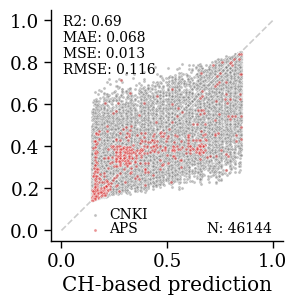

========== py_gender_weighted_pop_NU ==========


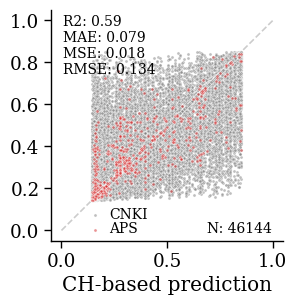

========== py_gender_avg_CNKI ==========


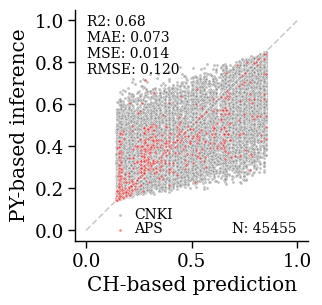

========== py_gender_weighted_pop_CNKI ==========


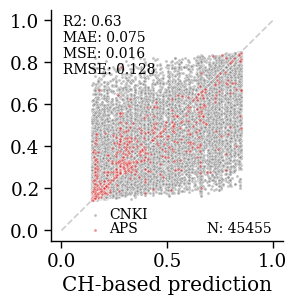

In [73]:
rmse_pred_py_test = None

for col, label in PINYIN_AGG_LABELS.items():

    print(f"========== {col} ==========")
    df = df_py.dropna(subset=[col]).drop_duplicates(subset=['py_givenname', 'ch_givenname'])
    # df = df_py_genders.reset_index().dropna(subset=[col]).drop_duplicates(subset=['py_givenname_aps', 'ch_givenname'])
    df[[col, 'ch_pred']] = df[[col, 'ch_pred']].astype(float)
    df_py_genders[[col, 'ch_pred']] = df_py_genders[[col, 'ch_pred']].astype(float)

    mae_pred, mse_pred, rmse_pred, r2_pred = numeric.get_performance(df, 'ch_pred', col)
    performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred}

    fn = ios.path_join(PLOT_DIR, f'{col}_vs_ch_gender.pdf')
    _, ax = vis.plot_regression_performance(df, 'ch_pred', col, 
                                    metrics = performance_py,
                                    figsize=(3, 3), 
                                    title=None,
                                    xlabel="CH-based prediction", 
                                    ylabel="PY-based inference" if col == 'py_gender_avg_CNKI' else None,
                                    markersize=5,
                                    markeralpha=0.5,
                                    fn=fn,
                                    datalabel='CNKI',
                                    additional_data = [{'x': df_py_genders['ch_pred'], 'y': df_py_genders[col], 'label': 'APS', 'color': 'tab:red'}]
                                    )
    vis.plt.show()
    vis.plt.close()


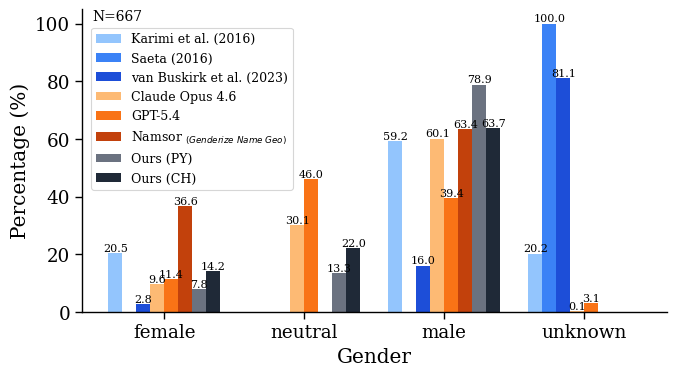

../../results/v3/gender/predictions_py_others/plots/py_gender_baseline_comparison.pdf


In [ ]:
from matplotlib import hatch

fn = f'{PLOT_OTHERS_DIR}/py_gender_baseline_comparison.pdf'

fig, ax = vis.plot_gender_comparison(
    df_py_genders,
    method_order=METHOD_ORDER,
    method_labels=METHOD_LABELS,
    xlabel_order=['female', 'neutral', 'male', 'unknown'],
    colors = COLOR_METHODS,
    hatches = HATCH_METHODS,
    use_percentages=True,
    annotate_bars=True,
    title=None,
    fn = fn,
    n_annotation_kwargs={"fontsize": 10, "x": 0.06, "y":1.0, "ha": "center"} ,
    legend_kwargs={"loc": "upper left", "bbox_to_anchor": (0.005, 0.96), 'fontsize': 9},
    figsize=(7, 4.0),
)
vis.plt.show()
vis.plt.close()
print(fn)

In [ ]:

# 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
agreement_gt_ch = categorical.pairwise_agreement(df_py_genders, METHOD_ORDER)
print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
display(agreement_gt_ch.round(2))

# 2) Cohen's Kappa — agreement corrected for chance
kappa_gt_ch = categorical.pairwise_kappa(df_py_genders, METHOD_ORDER)
print("\nCohen's Kappa matrix (chance-corrected agreement):")
display(kappa_gt_ch.round(2))

Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,py_gender_karimi,py_gender_saeta,py_gender_buskirk,py_gender_claude,py_gender_gpt,py_gender_namsor,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.20,0.28,0.42,0.33,0.51,0.52,0.45
py_gender_saeta,0.20,1.00,0.81,0.00,0.03,0.00,0.00,0.00
py_gender_buskirk,0.28,0.81,1.00,0.12,0.12,0.14,0.15,0.12
py_gender_claude,0.42,0.00,0.12,1.00,0.75,0.62,0.65,0.70
py_gender_gpt,0.33,0.03,0.12,0.75,1.00,0.48,0.51,0.58
py_gender_namsor,0.51,0.00,0.14,0.62,0.48,1.00,0.64,0.62
py_gender_mv,0.52,0.00,0.15,0.65,0.51,0.64,1.00,0.72
ch_pred_label,0.45,0.00,0.12,0.70,0.58,0.62,0.72,1.00



Cohen's Kappa matrix (chance-corrected agreement):


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,py_gender_karimi,py_gender_saeta,py_gender_buskirk,py_gender_claude,py_gender_gpt,py_gender_namsor,py_gender_mv,ch_pred_label
py_gender_karimi,1.00,0.0,0.02,0.07,0.09,0.11,0.07,0.07
py_gender_saeta,0.00,NaN,0.00,0.00,0.00,0.00,0.00,0.00
py_gender_buskirk,0.02,0.0,1.00,0.02,0.03,0.03,0.03,0.02
py_gender_claude,0.07,0.0,0.02,1.00,0.58,0.35,0.27,0.45
py_gender_gpt,0.09,0.0,0.03,0.58,1.00,0.27,0.21,0.33
py_gender_namsor,0.11,0.0,0.03,0.35,0.27,1.00,0.24,0.29
py_gender_mv,0.07,0.0,0.03,0.27,0.21,0.24,1.00,0.39
ch_pred_label,0.07,0.0,0.02,0.45,0.33,0.29,0.39,1.00


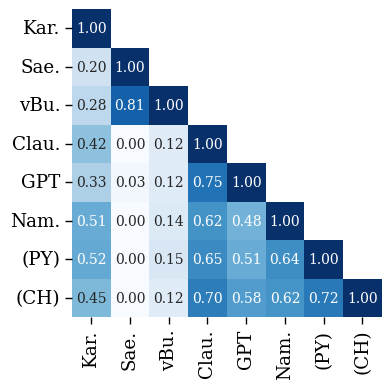

../../results/v3/gender/predictions_py_others/plots/py_gender_pairwise_agreement.pdf


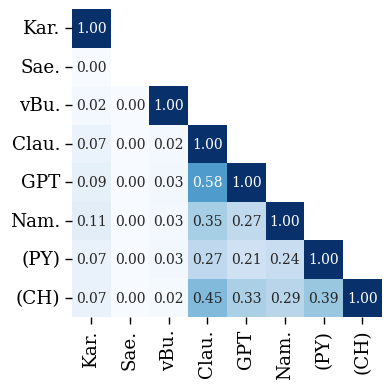

../../results/v3/gender/predictions_py_others/plots/py_gender_pairwise_kappa.pdf


In [ ]:

for kind, arr in {'agreement':agreement_gt_ch,'kappa':kappa_gt_ch}.items():
    arr = arr.to_numpy()
    arr[numeric.np.triu_indices(arr.shape[0], k=1)] = numeric.np.nan
    fn = f'{PLOT_OTHERS_DIR}/py_gender_pairwise_{kind}.pdf'
    vis.plot_confusion_matrix(arr, [METHOD_LABELS_SHORT[m] for m in METHOD_ORDER], 
                            title=None,
                            xlabel=None,
                            ylabel=None,
                            cbar=False,
                            annot_kws={'fontsize': 10},
                            cmap='Blues', figsize=(4., 4.),
                            fn=fn,
                            )
    print(fn)